# P2 · EDA & Phân nhóm demand — Bước 2–3 · 9

**Mục tiêu.** Mô tả đặc tính nhu cầu của tập M5, phân nhóm theo khung **SBC** (Syntetos–Boylan–Croston),
và tổng hợp **khuyến nghị "nhu cầu nào → dùng model nào"** dựa trên kết quả đánh giá của P5.

**Input (cell đầu tự nạp):** `common/segment_labels.parquet` (nhãn SBC + ADI/CV²/zero_rate cho toàn bộ
30.490 chuỗi, do P1 tính), `common/sample_ids.csv`, `data/processed/data_long.parquet` (mẫu 3.474 chuỗi).

**Output (cell cuối tự lưu):** `data/outputs/p2_*.parquet` (bảng phân bố nhóm, EDA, mùa vụ, SNAP, khuyến nghị).

**Bố cục:** (1) Phân nhóm SBC & phân bố nhóm — (2) EDA đặc tính nhu cầu (nhu cầu, giá, sự kiện, mùa vụ,
SNAP) — (3) Khuyến nghị model theo nhóm (bước 9).

> Chạy được **cell đầu** (thấy `✅ Input sẵn sàng`) = đủ input để làm phần của mình.

## Cell đầu — import + nạp input (chạy được = sẵn sàng)

In [1]:
from pathlib import Path
def _need(p, hint):
    assert Path(p).exists(), f"THIẾU INPUT: {p}  →  {hint}"

import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
%matplotlib inline
_need("common/config.yaml", "clone repo")
_need("common/segment_labels.parquet", "clone repo (P1 đã tạo)")
_need("common/sample_ids.csv", "clone repo (P1 đã tạo)")
_need("data/processed/data_long.parquet", "chạy P1.ipynb hoặc tải data_long P1 gửi vào data/processed/")
CFG = yaml.safe_load(open("common/config.yaml", encoding="utf-8"))
SEED = CFG["seed"]; SP = CFG["split"]; SBC = CFG["sbc"]; SAMP = CFG["sampling"]
ADI_TH, CV2_TH = SBC["adi_threshold"], SBC["cv2_threshold"]
ID_COLS = ["id","item_id","dept_id","cat_id","store_id","state_id"]
order = ["smooth", "erratic", "intermittent", "lumpy"]
seg_colors = {"smooth":"#4C72B0","erratic":"#DD8452","intermittent":"#55A868","lumpy":"#C44E52"}

seg = pd.read_parquet("common/segment_labels.parquet")
sample_ids = pd.read_csv("common/sample_ids.csv")["series_id"].tolist()
long = pd.read_parquet("data/processed/data_long.parquet")
print("✅ Input sẵn sàng — long", long.shape, "| nhãn", seg.shape, "| mẫu", len(sample_ids))

✅ Input sẵn sàng — long (6743034, 24) | nhãn (30490, 5) | mẫu 3474


## 1. Phân nhóm demand theo khung SBC

**Phương pháp.** Mỗi chuỗi được đặc trưng bởi hai đại lượng tính **chỉ trên khoảng train** (tránh rò rỉ):
- **ADI** (Average Demand Interval) = số ngày / số ngày có bán > 0 → đo *mức độ gián đoạn* (càng lớn càng thưa).
- **CV²** = (σ/μ)² của nhu cầu các ngày có bán > 0 → đo *mức độ biến động cỡ nhu cầu*.

Áp ngưỡng SBC (Syntetos–Boylan 2005) **ADI = 1.32**, **CV² = 0.49** chia 4 nhóm:
`smooth` (đều & ổn định), `erratic` (đều nhưng biến động mạnh), `intermittent` (thưa & ổn định),
`lumpy` (thưa & biến động mạnh). Nhãn do **P1** tính sẵn cho cả 30.490 chuỗi; P2 **tổng hợp, không tính lại**.

Bảng phân bố dùng **median** cho ADI/CV² (phân phối lệch phải mạnh, trung vị bền với ngoại lai hơn trung bình).

     segment  n_series  zero_rate   ADI   CV2   pct
      smooth       980      0.138 1.177 0.374  3.21
     erratic       494      0.167 1.216 0.614  1.62
intermittent     23095      0.738 4.598 0.298 75.75
       lumpy      5921      0.604 2.503 0.619 19.42


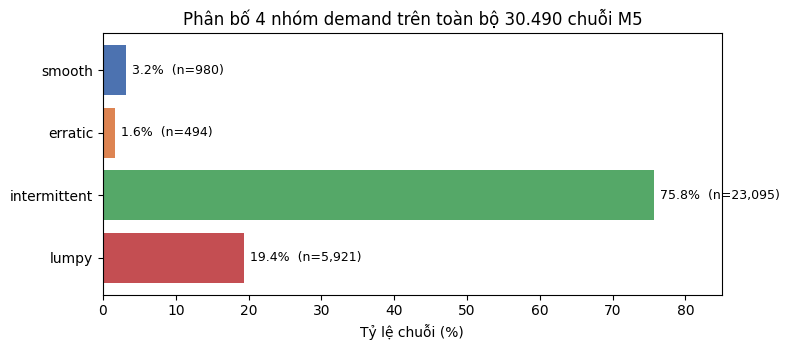

In [2]:
# Bảng phân bố 4 nhóm (toàn bộ 30.490 chuỗi)
summary = (seg.groupby("segment")
             .agg(n_series=("series_id", "size"),
                  zero_rate=("zero_rate", "mean"),
                  ADI=("ADI", "median"),
                  CV2=("CV2", "median"))
             .reindex(order))
summary["pct"] = (summary["n_series"] / summary["n_series"].sum() * 100).round(2)
summary = summary.reset_index()
print(summary.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(summary["segment"], summary["pct"], color=[seg_colors[s] for s in summary["segment"]])
ax.invert_yaxis(); ax.set_xlabel("Tỷ lệ chuỗi (%)")
ax.set_title("Phân bố 4 nhóm demand trên toàn bộ 30.490 chuỗi M5")
for b, n in zip(bars, summary["n_series"]):
    ax.text(b.get_width() + 0.8, b.get_y() + b.get_height()/2,
            f"{b.get_width():.1f}%  (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, 85); fig.tight_layout(); plt.show()

**Nhận xét.** Phân bố **cực kỳ mất cân bằng**: hai nhóm *thưa* chiếm **~95%** tổng chuỗi
(`intermittent` 75.8% + `lumpy` 19.4%), trong khi `smooth` chỉ 3.2% và `erratic` 1.6%. Điều này phản ánh
đúng bản chất bán lẻ M5 — phần lớn SKU bán lẻ tẻ, nhiều ngày = 0 (zero-rate `intermittent` ≈ 0.74,
`lumpy` ≈ 0.60). **Hệ quả cho nghiên cứu:** (i) các metric điểm (RMSSE) kém ý nghĩa với chuỗi thưa → ưu
tiên **dự báo xác suất** (SPL/WSPL, coverage); (ii) đánh giá phải **tách theo nhóm** để nhóm thưa không
"nuốt" tín hiệu; (iii) nếu tổng hợp toàn tập cần **trọng số theo tần suất** để kết luận đại diện đúng.

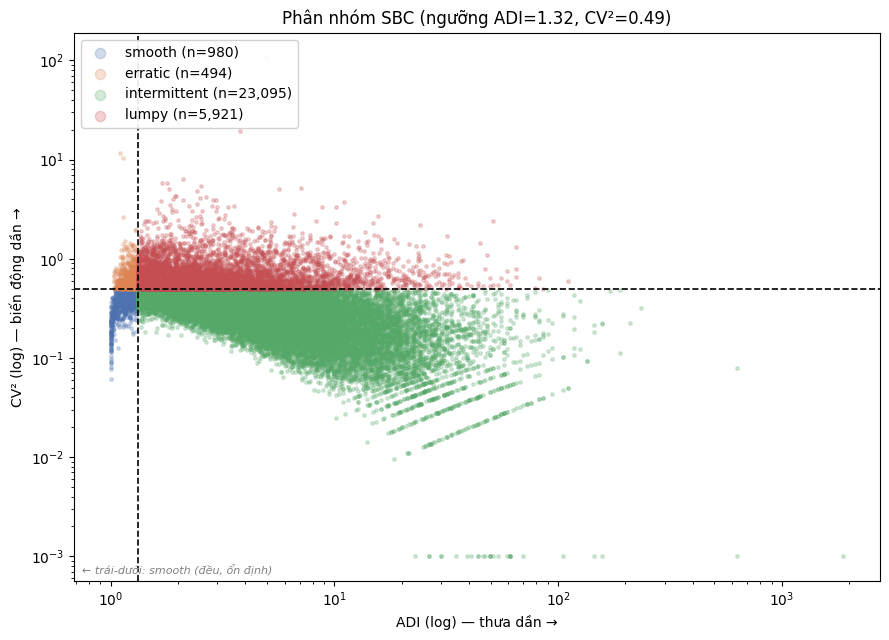

In [3]:
# Biểu đồ phân nhóm SBC: ADI vs CV² (log-log) + đường ngưỡng
cv2_plot = seg["CV2"].clip(lower=1e-3)   # clip để hiện được trên trục log (CV²=0 khi chuỗi có cỡ bán hằng)
fig, ax = plt.subplots(figsize=(9, 6.5))
for s in order:
    m = seg["segment"] == s
    ax.scatter(seg.loc[m, "ADI"], cv2_plot[m], s=6, alpha=0.25,
               color=seg_colors[s], label=f"{s} (n={m.sum():,})")
ax.axvline(ADI_TH, ls="--", color="black", lw=1.2)
ax.axhline(CV2_TH, ls="--", color="black", lw=1.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ADI (log) — thưa dần →"); ax.set_ylabel("CV² (log) — biến động dần →")
ax.set_title(f"Phân nhóm SBC (ngưỡng ADI={ADI_TH}, CV²={CV2_TH})")
ax.text(0.01, 0.01, "← trái-dưới: smooth (đều, ổn định)", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=8, color="gray", style="italic")
ax.legend(markerscale=3, framealpha=0.9, loc="upper left")
fig.tight_layout(); plt.show()

**Nhận xét.** Scatter xác nhận trực quan ranh giới 4 nhóm quanh hai đường ngưỡng. Khối điểm dồn mạnh
về phía **ADI lớn** (bên phải) = đa số chuỗi thưa, khớp với bảng phân bố. Trục CV² trải rộng (tới ~10²)
cho thấy ngay trong nhóm thưa, *cỡ* mỗi lần bán cũng dao động lớn (→ `lumpy`). Ranh giới dọc (ADI=1.32)
là yếu tố tách chính: rất ít chuỗi nằm ở vùng "đều" (bên trái).

## 2. EDA đặc tính nhu cầu theo nhóm

Phân tích trên **mẫu phân tầng 3.474 chuỗi** (`data_long`). Mục tiêu: mô tả nhu cầu, giá, và phản ứng
với **sự kiện / mùa vụ / SNAP** — các yếu tố ngoại sinh mà model (nhất là ML/FM) có thể khai thác.

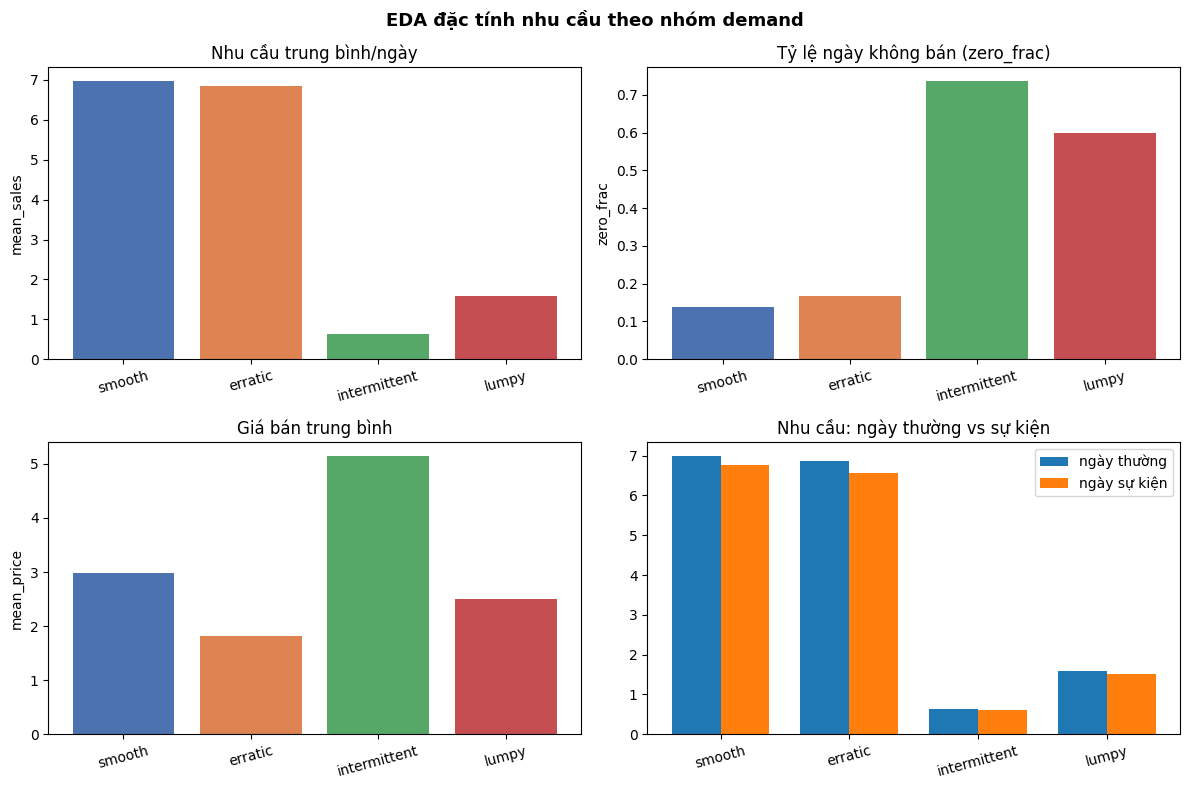

In [4]:
# 2.1 Nhu cầu, zero-rate, giá, và tác động sự kiện theo nhóm
demand = (long.groupby("segment")
              .agg(mean_sales=("sales", "mean"),
                   zero_frac=("sales", lambda s: float((s == 0).mean())),
                   mean_price=("sell_price", "mean"))
              .reindex(order))
ev = (long.groupby(["segment", "is_event"])["sales"].mean()
          .unstack("is_event").rename(columns={0: "sales_non_event", 1: "sales_event"})
          .reindex(order))
demand = demand.join(ev).reset_index()

colors = [seg_colors[s] for s in demand["segment"]]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].bar(demand["segment"], demand["mean_sales"], color=colors)
axes[0,0].set_title("Nhu cầu trung bình/ngày"); axes[0,0].set_ylabel("mean_sales")
axes[0,1].bar(demand["segment"], demand["zero_frac"], color=colors)
axes[0,1].set_title("Tỷ lệ ngày không bán (zero_frac)"); axes[0,1].set_ylabel("zero_frac")
axes[1,0].bar(demand["segment"], demand["mean_price"], color=colors)
axes[1,0].set_title("Giá bán trung bình"); axes[1,0].set_ylabel("mean_price")
x = np.arange(len(demand)); w = 0.38
axes[1,1].bar(x - w/2, demand["sales_non_event"], w, label="ngày thường")
axes[1,1].bar(x + w/2, demand["sales_event"], w, label="ngày sự kiện")
axes[1,1].set_xticks(x); axes[1,1].set_xticklabels(demand["segment"])
axes[1,1].set_title("Nhu cầu: ngày thường vs sự kiện"); axes[1,1].legend()
for ax in axes.flat: ax.tick_params(axis="x", rotation=15)
fig.suptitle("EDA đặc tính nhu cầu theo nhóm demand", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

**Nhận xét.** (i) Nhu cầu/ngày giảm mạnh theo trục gián đoạn: `smooth`≈7.0 và `erratic`≈6.8, nhưng
`intermittent` chỉ ≈0.63 và `lumpy`≈1.58 — chênh **~10 lần**, củng cố việc tách nhóm khi đánh giá. (ii)
`zero_frac` khớp định nghĩa SBC (thưa ⇒ nhiều 0). (iii) Giá `intermittent` cao nhất (≈5.1) gợi ý các mặt
hàng đắt/ít mua. (iv) **Sự kiện gần như không làm tăng nhu cầu trung bình** (thậm chí giảm nhẹ ở mọi
nhóm) — tác động lễ ở M5 mang tính *cục bộ theo loại sự kiện/mặt hàng* chứ không đồng đều, nên feature
event cần dùng ở mức chi tiết (từng loại) thay vì cờ nhị phân tổng.

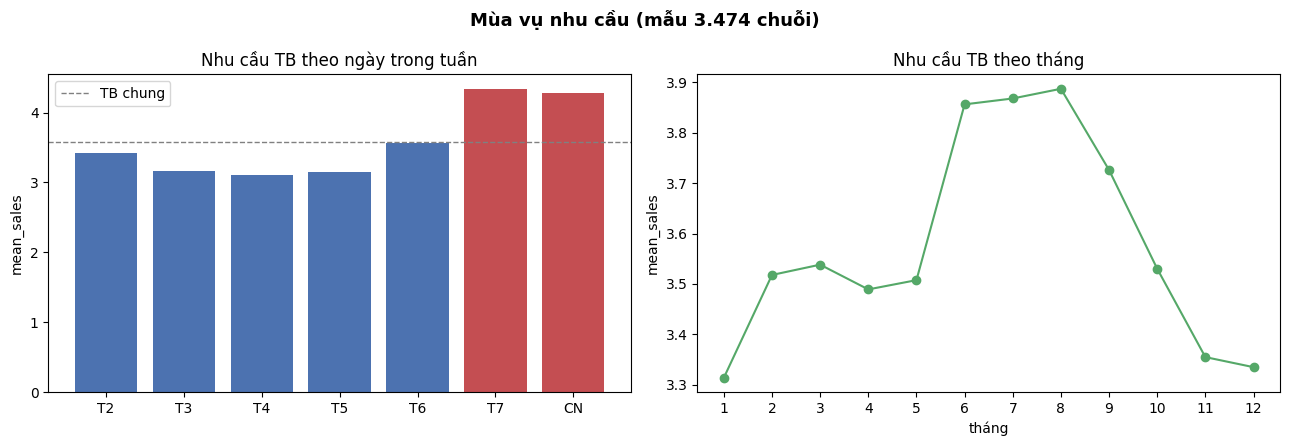

In [5]:
# 2.2 Mùa vụ: theo ngày trong tuần và theo tháng
day_order = [3, 4, 5, 6, 7, 1, 2]           # M5: wday 1=T7,2=CN,3=T2..7=T6 → xếp lại T2..CN
day_lab   = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
sw = long.groupby("wday")["sales"].mean().reindex(day_order)
sm = long.groupby("month")["sales"].mean()
season_wday  = pd.DataFrame({"weekday": day_lab, "mean_sales": sw.values})
season_month = sm.rename_axis("month").reset_index(name="mean_sales")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
wcol = ["#C44E52" if d in ("T7", "CN") else "#4C72B0" for d in day_lab]
ax[0].bar(day_lab, sw.values, color=wcol)
ax[0].set_title("Nhu cầu TB theo ngày trong tuần"); ax[0].set_ylabel("mean_sales")
ax[0].axhline(long["sales"].mean(), ls="--", color="gray", lw=1, label="TB chung")
ax[0].legend()
ax[1].plot(sm.index, sm.values, marker="o", color="#55A868")
ax[1].set_xticks(range(1, 13)); ax[1].set_title("Nhu cầu TB theo tháng")
ax[1].set_xlabel("tháng"); ax[1].set_ylabel("mean_sales")
fig.suptitle("Mùa vụ nhu cầu (mẫu 3.474 chuỗi)", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

**Nhận xét.** **Mùa vụ tuần rõ rệt:** cuối tuần (**T7≈4.33, CN≈4.28**) cao hơn ngày thường
(~3.1–3.4) khoảng **+31%** — hiệu ứng mua sắm cuối tuần. **Mùa vụ năm nhẹ hơn:** đỉnh **tháng 8** (≈3.89)
và đáy **tháng 1** (≈3.31, hậu lễ hội). ⇒ Feature `wday` (và tương tác cuối tuần) là tín hiệu giá trị cho
P3/P4; chu kỳ tuần (7 ngày) biện minh cho baseline **SeasonalNaive(7)**.

     segment  non_snap  snap  uplift_pct
      smooth     6.718 7.471   11.200000
     erratic     6.538 7.443   13.800000
intermittent     0.611 0.670    9.700000
       lumpy     1.498 1.741   16.200001


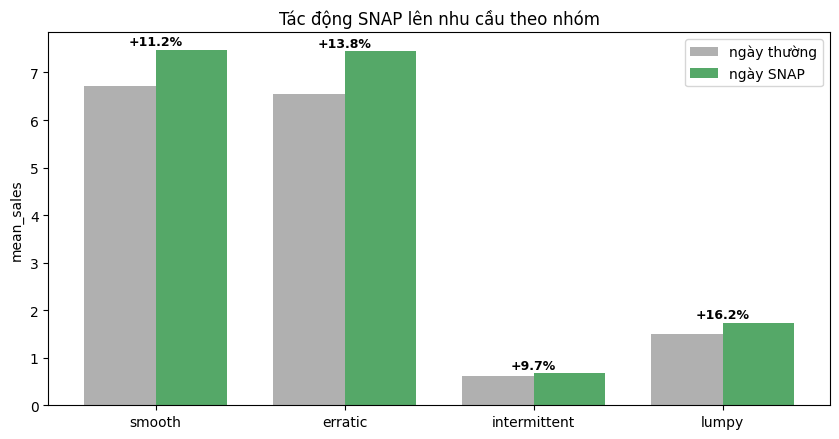

In [6]:
# 2.3 Tác động SNAP (ngày phát trợ cấp thực phẩm) theo nhóm
snap_effect = (long.groupby(["segment", "snap"])["sales"].mean()
                   .unstack("snap").rename(columns={0: "non_snap", 1: "snap"})
                   .reindex(order))
snap_effect["uplift_pct"] = ((snap_effect["snap"] / snap_effect["non_snap"] - 1) * 100).round(1)
snap_effect = snap_effect.reset_index()
print(snap_effect.round(3).to_string(index=False))

x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(x - w/2, snap_effect["non_snap"], w, label="ngày thường", color="#B0B0B0")
ax.bar(x + w/2, snap_effect["snap"], w, label="ngày SNAP", color="#55A868")
for i, u in enumerate(snap_effect["uplift_pct"]):
    ax.text(i, max(snap_effect.loc[i, "snap"], snap_effect.loc[i, "non_snap"]) + 0.1,
            f"+{u:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("mean_sales"); ax.set_title("Tác động SNAP lên nhu cầu theo nhóm")
ax.legend(); fig.tight_layout(); plt.show()

**Nhận xét.** SNAP **làm tăng nhu cầu ở mọi nhóm** (uplift dương toàn bộ): mạnh nhất ở `lumpy`
(**+16.2%**) và `erratic` (**+13.8%**), thấp nhất ở `intermittent` (**+9.7%**). Đây là tín hiệu ngoại sinh
*ổn định hơn* so với cờ sự kiện — SNAP nên được giữ làm feature cho ML (P3) và là biến ngoại sinh tiềm năng
cho các model hỗ trợ covariate. Mức uplift khác nhau giữa nhóm cũng hàm ý **lợi ích của SNAP phụ thuộc đặc
tính chuỗi** (phù hợp luận điểm "nhu cầu nào → cách xử lý nào").

## 3. Khuyến nghị model theo nhóm (Bước 9)

Tổng hợp **kết luận có điều kiện** của nghiên cứu: với mỗi nhóm demand, model nào nên dùng. Nguồn: bảng
đánh giá của **P5** — `metrics_by_model_segment` (RMSSE/SPL/**WSPL**/coverage) và `decision_table` (đã gắn
nhãn thắng/tương đương theo **quy tắc: chênh sống sót qua ≥3 cửa sổ rolling-origin VÀ kiểm định
MCB/Diebold–Mariano, p < 0.05 → "thắng rõ"; ngược lại "tương đương"**).

In [7]:
# Bảng khuyến nghị model theo nhóm (dựa trên kết quả P5)
_need("data/outputs/metrics_by_model_segment.parquet", "cần P5 chạy xong — git pull lấy forecasts + metrics")
_need("data/outputs/decision_table.parquet", "cần P5 chạy xong — git pull")
metrics = pd.read_parquet("data/outputs/metrics_by_model_segment.parquet")
decision = pd.read_parquet("data/outputs/decision_table.parquet").rename(columns={
    "Nhóm demand": "segment", "Nên dùng (SPL)": "recommended_model",
    "Độ tin cậy": "confidence", "Chênh vs á quân (%)": "margin_pct"})
chosen = metrics.merge(decision[["segment", "recommended_model"]],
                       left_on=["segment", "model"], right_on=["segment", "recommended_model"])
recommendation = (decision
                  .merge(chosen[["segment", "SPL", "WSPL"]], on="segment", how="left")
                  .merge(summary[["segment", "n_series", "pct"]], on="segment", how="left")
                  .set_index("segment").reindex(order).reset_index())
print(recommendation.round(3).to_string(index=False))

     segment recommended_model  confidence  margin_pct   SPL  WSPL  n_series   pct
      smooth              lgbm tương đương         2.1 0.177 0.184       980  3.21
     erratic      chronos_bolt tương đương         2.6 0.200 0.305       494  1.62
intermittent              lgbm tương đương         2.8 0.230 0.242     23095 75.75
       lumpy              lgbm    thắng rõ         6.4 0.238 0.259      5921 19.42


**Nhận xét & bàn luận.**
- **LightGBM** là lựa chọn chủ đạo (thắng/ngang ở `smooth`, `intermittent`, `lumpy`); với **`lumpy`** nó
  **thắng rõ** (+6.4%, qua kiểm định) — nhóm chiếm ~19% chuỗi nên đây là kết luận có trọng lượng.
- **Chronos-Bolt** nhỉnh ở **`erratic`** nhưng chỉ ở mức *tương đương* (+2.6%, chưa qua ngưỡng ý nghĩa),
  và `erratic` chỉ 1.6% chuỗi → khuyến nghị này **yếu về bằng chứng**.
- Ba trong bốn nhóm ở mức **"tương đương"** ⇒ kết luận trung thực là **"không có model thắng tuyệt đối;
  ưu thế phụ thuộc nhóm demand và thường nằm trong sai số thống kê"** — đúng tinh thần kết luận *có điều
  kiện & có kiểm định* của plan.

> ℹ️ Lưu ý về **rò rỉ pre-training** của foundation model (Chronos/TTM) được trình bày tập trung trong
> `docs/plan/PLAN_REVISED.md` để cả nhóm (nhất là P4 — người triển khai FM) theo dõi.

## Cell cuối — lưu output

In [8]:
# Lưu toàn bộ bảng kết quả để P1 tổng hợp báo cáo
Path("data/outputs").mkdir(parents=True, exist_ok=True)
summary.to_parquet("data/outputs/p2_segment_summary.parquet", index=False)
demand.to_parquet("data/outputs/p2_demand_by_segment.parquet", index=False)
season_wday.to_parquet("data/outputs/p2_seasonality_wday.parquet", index=False)
season_month.to_parquet("data/outputs/p2_seasonality_month.parquet", index=False)
snap_effect.to_parquet("data/outputs/p2_snap_effect.parquet", index=False)
recommendation.to_parquet("data/outputs/p2_recommendation.parquet", index=False)
print("✅ Đã lưu 6 bảng p2_*.parquet vào data/outputs/")

✅ Đã lưu 6 bảng p2_*.parquet vào data/outputs/
